In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/raw_data.csv')

display(df.head())

df.info()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [2]:
print("Total Missing Values in dataset:", df.isnull().sum().sum())

Total Missing Values in dataset: 0


In [3]:
print("Duplicates before cleaning:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates before cleaning: 0


In [4]:
cols_to_drop = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')

In [5]:
print("Shape after cleaning:", df.shape)

Shape after cleaning: (1470, 31)


In [6]:
df.to_csv('../data/cleaned_data.csv', index=False)
print("✅ Cleaned data successfully saved as 'cleaned_data.csv' in the data folder!")

✅ Cleaned data successfully saved as 'cleaned_data.csv' in the data folder!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Key HR Metrics (KPIs) Calculate Karna ---
total_employees = len(df)
total_attrition = (df['Attrition'] == 'Yes').sum()
attrition_rate = (total_attrition / total_employees) * 100
avg_age = df['Age'].mean()

In [8]:
print("📊 --- Key HR Metrics (KPIs) ---")
print(f"Total Employees: {total_employees}")
print(f"Total Attrition: {total_attrition}")
print(f"Attrition Rate: {attrition_rate:.2f}%")
print(f"Average Age: {avg_age:.1f} years\n")

📊 --- Key HR Metrics (KPIs) ---
Total Employees: 1470
Total Attrition: 237
Attrition Rate: 16.12%
Average Age: 36.9 years



In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 5))

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

Text(0.5, 1.0, 'Impact of OverTime on Attrition')

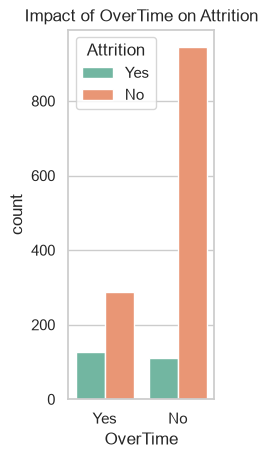

In [10]:
plt.subplot(1, 3, 1)
sns.countplot(x='OverTime', hue='Attrition', data=df, palette='Set2')
plt.title('Impact of OverTime on Attrition')

Text(0.5, 1.0, 'Job Satisfaction vs Attrition')

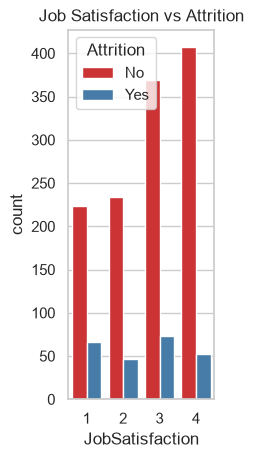

In [11]:
plt.subplot(1, 3, 2)
sns.countplot(x='JobSatisfaction', hue='Attrition', data=df, palette='Set1')
plt.title('Job Satisfaction vs Attrition')

C:\Users\SANDESH ANAND\AppData\Local\Temp\ipykernel_29592\3481833328.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, palette='Pastel1')


Text(0.5, 1.0, 'Monthly Income vs Attrition')

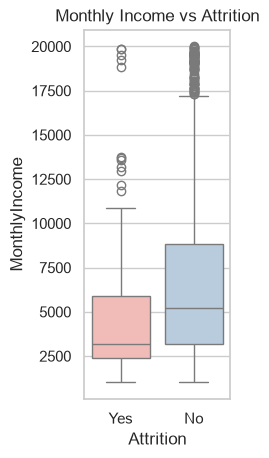

In [12]:
plt.subplot(1, 3, 3)
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, palette='Pastel1')
plt.title('Monthly Income vs Attrition')

In [13]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>